# Device Dominance and User Engagement Analysis
## Purpose: Analyze device market share and user engagement across states

C:\Users\Vijay\AppData\Local\Temp\ipykernel_38312\840285821.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


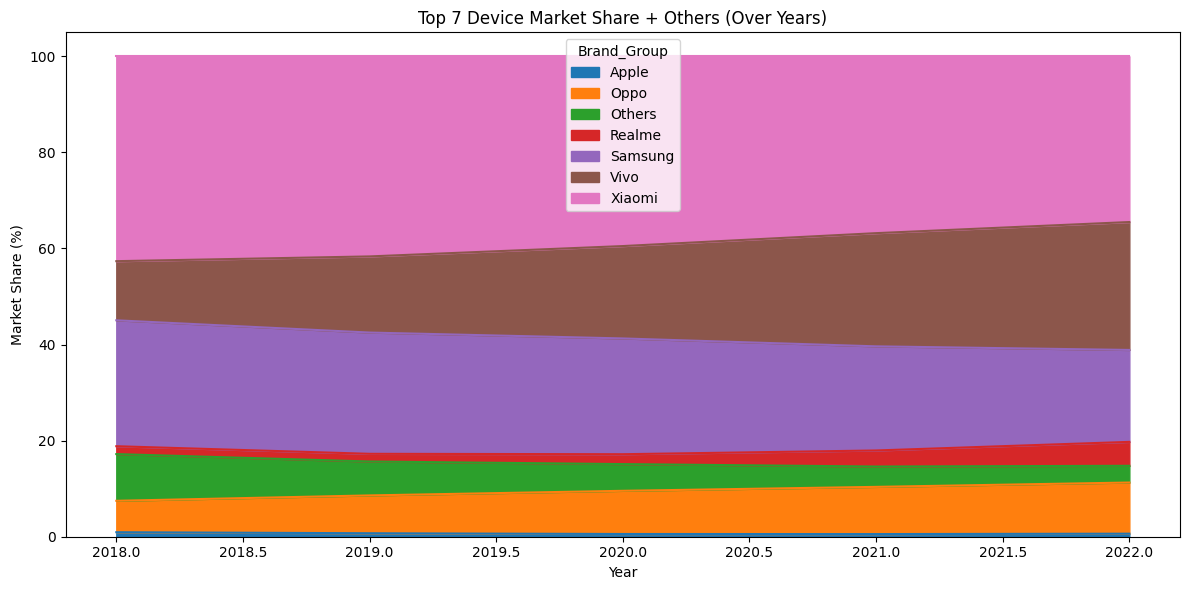

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector

# ------------------ DB CONNECTION ------------------
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="phonepe_db"
)

# =====================================================
        # QUERY: DEVICE SHARE (TOP 7 + OTHERS)
# =====================================================
query = """
WITH brand_totals AS (
    SELECT 
        Brand,
        SUM(ROUND(Registered_users * Percentage)) AS Total_Users
    FROM aggregated_user
    GROUP BY Brand
),

top_brands AS (
    SELECT Brand
    FROM brand_totals
    ORDER BY Total_Users DESC
    LIMIT 7
)

SELECT 
    Year,
    
    CASE 
        WHEN Brand IN (SELECT Brand FROM top_brands) THEN Brand
        ELSE 'Others'
    END AS Brand_Group,
    
    SUM(ROUND(Registered_users * Percentage)) AS Brand_Users

FROM aggregated_user
GROUP BY Year, Brand_Group;
"""

df = pd.read_sql(query, conn)

# ------------------ MARKET SHARE ------------------
total_per_year = df.groupby("Year")["Brand_Users"].transform("sum")
df["Market_Share"] = (df["Brand_Users"] / total_per_year) * 100

# ------------------ PIVOT ------------------
pivot_df = df.pivot(index="Year", columns="Brand_Group", values="Market_Share").fillna(0)

# ------------------ PLOT ------------------
pivot_df.plot.area(figsize=(12, 6))

plt.title("Top 7 Device Market Share + Others (Over Years)")
plt.xlabel("Year")
plt.ylabel("Market Share (%)")

plt.tight_layout()
plt.show()